# Do India's famous herbs reach the brain? 🧠🌿
### AI model to predict blood-brain barrier (BBB) penetration

**How to run this (very easy):**
1. Click **Runtime** (top menu) → **Run all**.
2. Wait 2 to 3 minutes. Scroll down. You will see numbers and charts appear under each cell.
3. If Colab shows a warning like "not authored by Google", click **Run anyway**.

Each cell below has a short explanation in simple words.

## Step 0: Install the tools
RDKit reads molecules. scikit-learn is the AI library.

In [1]:
!pip install -q rdkit scikit-learn matplotlib pandas

## Step 0b: Download the data
This downloads the BBBP dataset (about 2,000 molecules). Each one is labelled: crosses the brain barrier (1) or not (0).

In [9]:
!curl -sL -o bbbp.csv https://raw.githubusercontent.com/GLambard/Molecules_Dataset_Collection/master/latest/BBBP.csv
import pandas as pd
print(pd.read_csv("bbbp.csv").head())

   Unnamed: 0  num                  name  p_np  \
0           0    1            Propanolol     1   
1           1    2  Terbutylchlorambucil     1   
2           2    3                 40730     1   
3           3    4                    24     1   
4           4    5           cloxacillin     1   

                                              smiles  
0        CC(C)NCC(O)COC1:C:C:C:C2:C:C:C:C:C:1:2.[Cl]  
1       CC(C)(C)OC(=O)CCCC1:C:C:C(N(CCCl)CCCl):C:C:1  
2  CC1COC2:C(N3CCN(C)CC3):C(F):C:C3:C(=O):C(C(=O)...  
3               CC(=O)NCCCOC1:C:C:C:C(CN2CCCCC2):C:1  
4  CC1:O:N:C(C2:C:C:C:C:C:2Cl):C:1C(=O)N[C@@H]1C(...  


## Import the libraries

In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Crippen, rdMolDescriptors
from rdkit.Chem.rdMolDescriptors import CalcMolFormula
from rdkit.Chem import inchi
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, balanced_accuracy_score
RDLogger.DisableLog("rdApp.*")
SEED = 42

## Step 1: Load and clean the data
Read every molecule and remove salts so only the main molecule stays.

In [4]:
# ---------- 1. Load and clean the training data ----------
df = pd.read_csv("bbbp.csv")[["name", "p_np", "smiles"]]
def clean(smi):
    if not isinstance(smi, str): return None
    m = Chem.MolFromSmiles(smi)
    if m is None: return None
    frags = Chem.GetMolFrags(m, asMols=True)            # drop salts, keep the main molecule
    return max(frags, key=lambda x: x.GetNumHeavyAtoms())
df["mol"] = df["smiles"].apply(clean)
print(f"Loaded {len(df)} rows, kept {df['mol'].notnull().sum()} valid molecules")
df = df[df["mol"].notnull()].reset_index(drop=True)
print("BBB+ :", int(df.p_np.sum()), "  BBB- :", int((1 - df.p_np).sum()))

Loaded 2050 rows, kept 2039 valid molecules
BBB+ : 1560   BBB- : 479


## Step 2: Turn molecules into numbers
AI cannot read drawings. Each molecule becomes about 200 numbers (weight, polarity, rings, and so on). These are called descriptors.

In [5]:
# ---------- 2. Features ----------
names = [n for n, _ in Descriptors.descList]
def feats(m): return [f(m) for _, f in Descriptors.descList]
def tidy(a): return np.clip(np.nan_to_num(np.array(a, dtype=float), nan=0, posinf=0, neginf=0), -1e6, 1e6)
X = tidy([feats(m) for m in df["mol"]])
y = df["p_np"].values
tpsa = np.array([rdMolDescriptors.CalcTPSA(m) for m in df["mol"]])

## Step 3: Train the AI and test it
The AI learns from 80% of the molecules. Then we test it on the other 20% it has never seen. **ROC-AUC** tells how well it separates brain-crossing from non-crossing (1.0 = perfect). We also compare it with the classic rule: TPSA below 90.

In [6]:
# ---------- 3. Train / test ----------
idx = np.arange(len(df))
tr, te = train_test_split(idx, test_size=0.2, random_state=SEED, stratify=y)
rf = RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1, class_weight="balanced").fit(X[tr], y[tr])
p_te = rf.predict_proba(X[te])[:, 1]
auc_rf = roc_auc_score(y[te], p_te)
bal_rf = balanced_accuracy_score(y[te], p_te > 0.5)

# classic rule of thumb: molecules with TPSA < 90 A^2 tend to cross the BBB
auc_rule = roc_auc_score(y[te], -tpsa[te])
bal_rule = balanced_accuracy_score(y[te], tpsa[te] < 90)
print(f"Classic TPSA < 90 rule : ROC-AUC = {auc_rule:.3f}   balanced accuracy = {bal_rule:.3f}")
print(f"Random Forest (AI)     : ROC-AUC = {auc_rf:.3f}   balanced accuracy = {bal_rf:.3f}")
cv = cross_val_score(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1, class_weight="balanced"),
                     X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc")
print(f"Random Forest 5-fold CV ROC-AUC = {cv.mean():.3f} +/- {cv.std():.3f}")

Classic TPSA < 90 rule : ROC-AUC = 0.866   balanced accuracy = 0.738
Random Forest (AI)     : ROC-AUC = 0.962   balanced accuracy = 0.824
Random Forest 5-fold CV ROC-AUC = 0.934 +/- 0.013


## Step 4: Predict Indian herbal compounds
Each structure is checked against its published weight. Anything the AI already saw in training is removed so the test stays fair. Then the AI gives a probability (0 to 1) that each compound crosses the BBB.

In [7]:
# ---------- 4. Indian / Ayurvedic compounds (structures checked against published molecular weights) ----------
herbs = [
 ("Turmeric",        "Curcumin",       "COC1=C(C=CC(=C1)C=CC(=O)CC(=O)C=CC2=CC(=C(C=C2)O)OC)O", 368.38),
 ("Black pepper",    "Piperine",       "O=C(C=CC=Cc1ccc2OCOc2c1)N1CCCCC1", 285.34),
 ("Clove / Tulsi",   "Eugenol",        "COc1cc(CC=C)ccc1O", 164.20),
 ("Ginger",          "6-Gingerol",     "CCCCCC(O)CC(=O)CCc1ccc(O)c(OC)c1", 294.39),
 ("Amla",            "Gallic acid",    "OC(=O)c1cc(O)c(O)c(O)c1", 170.12),
 ("Many herbs",      "Quercetin",      "Oc1cc(O)c2c(c1)oc(-c1ccc(O)c(O)c1)c(O)c2=O", 302.24),
 ("Daruharidra",     "Berberine",      "COc1ccc2cc3[n+](cc2c1OC)CCc1cc2OCOc2cc1-3", 336.36),
 ("Ajwain",          "Thymol",         "Cc1ccc(C(C)C)c(O)c1", 150.22),
 ("Tulsi",           "Rosmarinic acid","OC(=O)C(Cc1ccc(O)c(O)c1)OC(=O)C=Cc1ccc(O)c(O)c1", 360.31),
 ("Chilli",          "Capsaicin",      "COc1cc(CNC(=O)CCCCC=CC(C)C)ccc1O", 305.41),
 ("Garlic",          "Allicin",        "C=CCS(=O)SCC=C", 162.27),
 ("Cinnamon",        "Cinnamaldehyde", "O=CC=Cc1ccccc1", 132.16),
 ("Kalmegh",         "Andrographolide","CC12CCC(C(C1CCC(=C)C2CC=C3C(COC3=O)O)(C)CO)O", 350.45),
 ("Vasaka",          "Vasicine",       "OC1CCN2Cc3ccccc3N=C12", 188.23),
 ("Fenugreek",       "Trigonelline",   "C[n+]1cccc(c1)C([O-])=O", 137.14),
 ("Sarpagandha",     "Reserpine",      "COC1=CC2=C(C=C1)C3=C(N2)C4CC5C(C(C(CC5CN4CC3)OC(=O)C6=CC(=C(C(=C6)OC)OC)OC)OC)C(=O)OC", 608.68),
]
# leakage check: never predict a molecule the model has already seen in training
ikey = lambda m: inchi.MolToInchiKey(m).split("-")[0]
train_keys = {ikey(m) for m in df["mol"]}
rows = []
for herb, cmpd, smi, mw_pub in herbs:
    m = Chem.MolFromSmiles(smi)
    if m is None or abs(Descriptors.MolWt(m) - mw_pub) > 0.6:
        print(f"SKIPPED {cmpd}: structure does not match published MW ({None if m is None else round(Descriptors.MolWt(m),2)} vs {mw_pub})")
        continue
    if ikey(m) in train_keys:
        print(f"REMOVED {cmpd}: already in the training data (would be an unfair test)"); continue
    x = tidy([feats(m)])
    rows.append({"Herb": herb, "Compound": cmpd, "Formula": CalcMolFormula(m), "MolWt": round(Descriptors.MolWt(m), 1),
                 "LogP": round(Crippen.MolLogP(m), 2), "TPSA": round(rdMolDescriptors.CalcTPSA(m), 1),
                 "P_BBB_plus": round(float(rf.predict_proba(x)[0, 1]), 2)})
res = pd.DataFrame(rows).sort_values("P_BBB_plus", ascending=False).reset_index(drop=True)
res["TPSA_rule"] = np.where(res["TPSA"] < 90, "pass", "fail")
print(res.to_string(index=False)); res.to_csv("ayurvedic_bbb_predictions.csv", index=False)

REMOVED Reserpine: already in the training data (would be an unfair test)
         Herb        Compound    Formula  MolWt  LogP  TPSA  P_BBB_plus TPSA_rule
 Black pepper        Piperine  C17H19NO3  285.3  3.00  38.8        0.95      pass
     Cinnamon  Cinnamaldehyde      C9H8O  132.2  1.90  17.1        0.95      pass
       Vasaka        Vasicine  C11H12N2O  188.2  1.30  35.8        0.93      pass
       Garlic         Allicin   C6H10OS2  162.3  1.76  17.1        0.90      pass
       Ajwain          Thymol    C10H14O  150.2  2.82  20.2        0.89      pass
  Daruharidra       Berberine C20H18NO4+  336.4  3.10  40.8        0.82      pass
    Fenugreek    Trigonelline    C7H7NO2  137.1 -1.13  44.0        0.81      pass
       Chilli       Capsaicin  C18H27NO3  305.4  3.79  58.6        0.75      pass
Clove / Tulsi         Eugenol   C10H12O2  164.2  2.13  29.5        0.73      pass
         Amla     Gallic acid     C7H6O5  170.1  0.50  98.0        0.65      fail
       Ginger      6-Gin

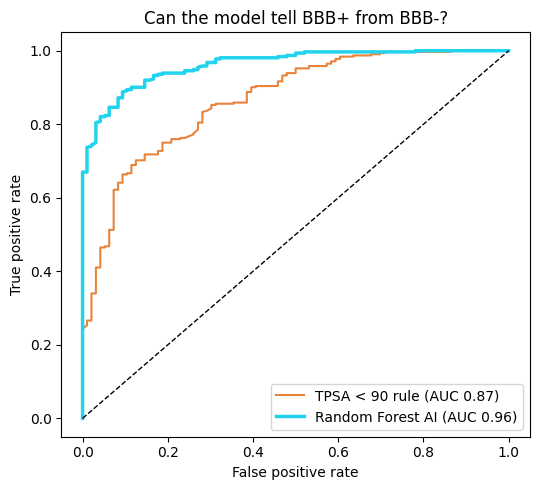

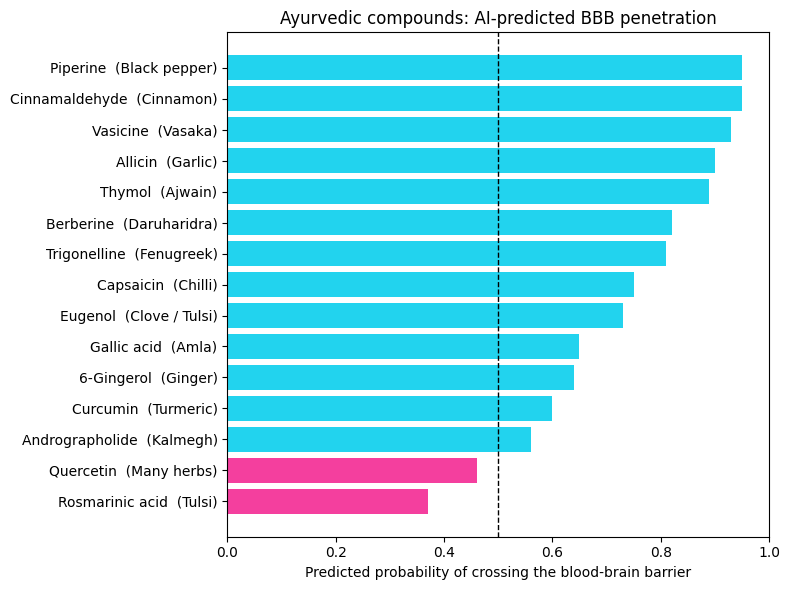

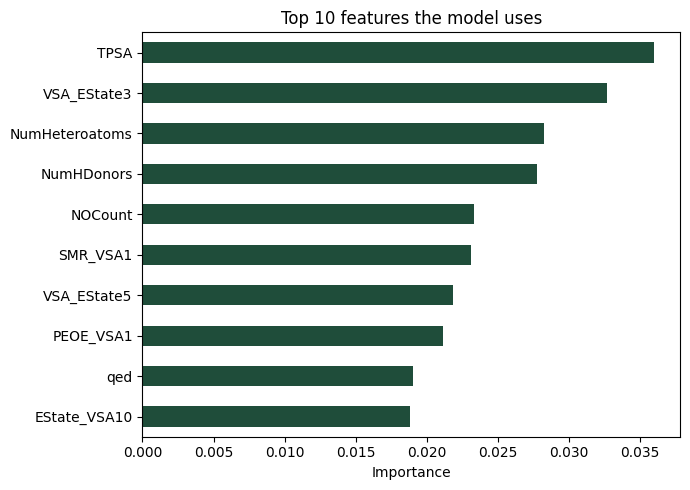

Top features: ['TPSA', 'VSA_EState3', 'NumHeteroatoms', 'NumHDonors', 'NOCount']


In [8]:
# ---------- 5. Figures ----------
fpr1, tpr1, _ = roc_curve(y[te], -tpsa[te]); fpr2, tpr2, _ = roc_curve(y[te], p_te)
plt.figure(figsize=(5.5, 5)); plt.plot(fpr1, tpr1, color="#E8833A", label=f"TPSA < 90 rule (AUC {auc_rule:.2f})")
plt.plot(fpr2, tpr2, color="#22D3EE", lw=2.5, label=f"Random Forest AI (AUC {auc_rf:.2f})"); plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("Can the model tell BBB+ from BBB-?"); plt.legend(); plt.tight_layout()
plt.show()

r = res.iloc[::-1]
plt.figure(figsize=(8, 6)); plt.barh(r["Compound"] + "  (" + r["Herb"] + ")", r["P_BBB_plus"], color=["#22D3EE" if p >= .5 else "#F43F9E" for p in r["P_BBB_plus"]])
plt.axvline(.5, color="k", ls="--", lw=1); plt.xlabel("Predicted probability of crossing the blood-brain barrier"); plt.xlim(0, 1)
plt.title("Ayurvedic compounds: AI-predicted BBB penetration"); plt.tight_layout(); plt.show()

imp = pd.Series(rf.feature_importances_, index=names).sort_values().tail(10)
plt.figure(figsize=(7, 5)); imp.plot.barh(color="#1F4D3A"); plt.title("Top 10 features the model uses"); plt.xlabel("Importance"); plt.tight_layout()
plt.show()
print("Top features:", list(imp.index[::-1][:5]))
pd.DataFrame({"Model": ["TPSA < 90 rule", "Random Forest"], "ROC_AUC": [auc_rule, auc_rf], "Balanced_accuracy": [bal_rule, bal_rf]}).to_csv("bbb_model_comparison.csv", index=False)

## Step 5: Charts
Chart 1 compares AI with the classic rule. Chart 2 shows the herbal predictions. Chart 3 shows what the AI looked at most.

## What do the results mean?
- The AI scored higher than the classic rule, so it is better at this task.
- Compounds above 50% are *predicted* likely to cross the barrier. Below 50% are *predicted* unlikely.
- **This is a computer prediction, not proof.** The model looks at structure only. It ignores absorption, metabolism and dose. Only lab studies can confirm.
- Dataset is small and from 2012. This is a learning project built with AI assistance.